# DPSIM Three Machines Infinite Bus Benchmark System - 6 Buses and 3 Generators

## SP/DP/EMT Test Cases

# RUN C++ examples

In [ ]:
import villas.dataprocessing.readtools as rt
from villas.dataprocessing.timeseries import TimeSeries as ts
import matplotlib.pyplot as plt
import pandas as pd
import re
import numpy as np
import math
import dpsimpy
from pathlib import Path

# %matplotlib widget

/usr/local/lib/python3.13/site-packages/villas/dataprocessing/readtools.py:143: SyntaxWarning: invalid escape sequence '\['
  if re.search('\[D\] Stamping .+ into system matrix:', log_lines[line_pos]):
/usr/local/lib/python3.13/site-packages/villas/dataprocessing/readtools.py:145: SyntaxWarning: invalid escape sequence '\['
  elif re.search('\[I\] System matrix:', log_lines[line_pos]):
/usr/local/lib/python3.13/site-packages/villas/dataprocessing/readtools.py:147: SyntaxWarning: invalid escape sequence '\['
  elif re.search('\[D\] Stamping .+ into source vector:', log_lines[line_pos]):
/usr/local/lib/python3.13/site-packages/villas/dataprocessing/readtools.py:149: SyntaxWarning: invalid escape sequence '\['
  elif re.search('\[I\] Right side vector:', log_lines[line_pos]):
/usr/local/lib/python3.13/site-packages/villas/dataprocessing/readtools.py:151: SyntaxWarning: invalid escape sequence '\['
  elif re.search('\[I\] LU decomposition:', log_lines[line_pos]):
/usr/local/lib/python3.13/

# Imports and System Parameters

In [2]:
# Simplified dynamic model rather than an exact reproduction of all four Texas files - without the SCRX excitation systems.

# ----------- Power System Base (Texas A&M 3MIB Benchmark) -----------

# Voltage levels, base impedances, and nominal frequency are taken from the PSS/E .RAW file

F_NOM = 60.0                          # Nominal grid frequency (Hz)
OMEGA_NOM = 2.0 * np.pi * F_NOM       # Nominal angular frequency (rad/s)
S_BASE = 100e6                        # System MVA base (100 MVA)
V_HV = 500e3                          # Transmission voltage level - Buses 4, 5, 6 (500 kV L-L RMS)
V_LV = 18e3                           # Generator terminal voltage level - Buses 1, 2, 3 (18 kV L-L RMS)
Z_BASE_HV = V_HV**2 / S_BASE          # Base impedance on 500 kV side (2500.0 Ohms)
TRAFO_RATING = 10_000e6               # Transformer MVA rating from .RAW file

# ----------- Synchronous Generators (4th-Order VBR Parameters on Machine Base) -----------

GENERATORS = {
    1: dict(name="G1", S_nom=1560e6, V_nom=V_LV, P=1404e6, Q_init=434.409e6, V_set_pu=1.04,
            H=4.500, Ld=0.890, Lq=0.660, L0=0.087, Ld_t=0.360, Lq_t=0.290, Td0_t=5.100, Tq0_t=0.094),
    2: dict(name="G2", S_nom=1560e6, V_nom=V_LV, P=1404e6, Q_init=434.409e6, V_set_pu=1.04,
            H=4.500, Ld=0.890, Lq=0.660, L0=0.087, Ld_t=0.360, Lq_t=0.290, Td0_t=5.100, Tq0_t=0.094),
    3: dict(name="G3", S_nom=890e6,  V_nom=V_LV, P=800e6,  Q_init=466.250e6, V_set_pu=1.02,
            H=3.859, Ld=1.720, Lq=1.679, L0=0.130, Ld_t=0.488, Lq_t=0.800, Td0_t=5.300, Tq0_t=0.625),
}

# ----------- Constant-PQ Loads from .RAW File (W, var) -----------
# Out-of-service load ID 2 at Bus 5 (0 MW / 0 Mvar) is excluded

LOADS = {
    4: (1400e6, 100e6),
    5: (2000e6, 100e6),
    6: (10000e6, 2000e6),
}

# ----------- Step-Up Transformers & Transmission Lines (100 MVA Base -> SI Henries) -----------

def x_pu_to_L_h(x_pu):
    return (x_pu * Z_BASE_HV) / OMEGA_NOM

# the .RAW file conflicts with the .EPC Voltage values. THe values used are 500 kV for the HV side and 18 kV for the LV side, which are consistent with the generator terminal voltage levels.

TRANSFORMERS = {
    "T14": dict(lv_bus=1, hv_bus=4, x_pu=0.00641),
    "T24": dict(lv_bus=2, hv_bus=4, x_pu=0.00641),
    "T35": dict(lv_bus=3, hv_bus=5, x_pu=0.01120),
}

LINES = {
    "L45": dict(from_bus=4, to_bus=5, x_pu=0.03600),
    "L56": dict(from_bus=5, to_bus=6, x_pu=0.12000),
}

# Target steady-state voltages from PSS/E .RAW (angles shifted so Bus 6 = 0 deg)
EXPECTED_PF = {
    1: (1.040000, 50.57213),
    2: (1.040000, 50.57213),
    3: (1.020000, 20.04792),
    4: (1.016913, 45.69061),
    5: (0.972777, 14.86700),
    6: (1.000000,  0.00000),
}

# ----------- Fault Switch & Simulation Settings -----------
switch_open = 1e9
switch_closed = 1e-2                  # Small closed resistance prevents singular matrix in EMT
fault_bus = 4                         # Apply 3-phase fault at 500 kV Bus 4

sim_name = "3MIB_4thOrder"
final_time = 3.0                      # Total simulation time (s)
time_step_sp = 1e-3                   # 1 ms step for SP phasor simulation
time_step_emt = 25e-6                 # 25 us step for EMT 3-phase waveform simulation
start_time_fault = 1.0                # Exact multiple of both time_step_sp and time_step_emt
end_time_fault = 1.1                  # 100 ms fault clearing time (6 cycles at 60 Hz)

Path("logs").mkdir(exist_ok=True)

# Power Flow Initialization
SP + NRP

In [3]:
sim_name_pf = sim_name + "_PF"
dpsimpy.Logger.set_log_dir("logs/" + sim_name_pf)

nodes_pf = {i: dpsimpy.sp.SimNode(f"n{i}", dpsimpy.PhaseType.Single) for i in range(1, 7)}
components_pf = []
gen_pf = {}

# 1. Local Synchronous Generators (PV Buses at 18 kV)
for bus, p in GENERATORS.items():
    gen = dpsimpy.sp.ph1.SynchronGenerator(p["name"], dpsimpy.LogLevel.info)
    gen.set_parameters(
        p["S_nom"], p["V_nom"], p["P"], p["V_nom"] * p["V_set_pu"],
        dpsimpy.PowerflowBusType.PV, p["Q_init"], 9.9e9, -9.9e9
    )
    gen.set_base_voltage(V_LV)
    gen.connect([nodes_pf[bus]])
    components_pf.append(gen)
    gen_pf[bus] = gen

# 2. Constant-PQ Loads (Buses 4, 5, and 6)
for bus, (p_load, q_load) in LOADS.items():
    load = dpsimpy.sp.ph1.Load(f"Load_bus{bus}", dpsimpy.LogLevel.info)
    load.set_parameters(p_load, q_load, V_LV if bus < 4 else V_HV)
    load.connect([nodes_pf[bus]])
    components_pf.append(load)

# 3. Infinite Bus / Slack Source at Bus 6 (VD Bus at 500 kV)
slack_pf = dpsimpy.sp.ph1.NetworkInjection("SlackBus", dpsimpy.LogLevel.info)
slack_pf.set_parameters(V_HV)  # 1.0 pu voltage set-point
slack_pf.set_base_voltage(V_HV)
slack_pf.modify_power_flow_bus_type(dpsimpy.PowerflowBusType.VD)
slack_pf.connect([nodes_pf[6]])
components_pf.append(slack_pf)

# 4. Step-Up Transformers (18 kV -> 500 kV)
for name, data in TRANSFORMERS.items():
    trafo = dpsimpy.sp.ph1.Transformer(name, dpsimpy.LogLevel.info)
    trafo.set_parameters(V_LV, V_HV, TRAFO_RATING, V_LV / V_HV, 0.0, 0.0, x_pu_to_L_h(data["x_pu"]))
    trafo.set_base_voltage(V_HV)
    trafo.connect([nodes_pf[data["lv_bus"]], nodes_pf[data["hv_bus"]]])
    components_pf.append(trafo)

# 5. Transmission Lines (500 kV)
for name, data in LINES.items():
    line = dpsimpy.sp.ph1.PiLine(name, dpsimpy.LogLevel.info)
    line.set_parameters(0.0, x_pu_to_L_h(data["x_pu"]), 0.0, 0.0)
    line.set_base_voltage(V_HV)
    line.connect([nodes_pf[data["from_bus"]], nodes_pf[data["to_bus"]]])
    components_pf.append(line)

system_pf = dpsimpy.SystemTopology(F_NOM, list(nodes_pf.values()), components_pf)

logger_pf = dpsimpy.Logger(sim_name_pf)
for bus, node in nodes_pf.items():
    logger_pf.log_attribute(f"v_bus{bus}", "v", node)

sim_pf = dpsimpy.Simulation(sim_name_pf, dpsimpy.LogLevel.info)
sim_pf.set_system(system_pf)
sim_pf.set_time_step(1.0)
sim_pf.set_final_time(2.0)
sim_pf.set_domain(dpsimpy.Domain.SP)
sim_pf.set_solver(dpsimpy.Solver.NRP)
sim_pf.set_solver_component_behaviour(dpsimpy.SolverBehaviour.Initialization)
sim_pf.do_init_from_nodes_and_terminals(False)
sim_pf.add_logger(logger_pf)
sim_pf.run()

# Verify solved Power Flow voltages against PSS/E .RAW targets
res_pf = rt.read_timeseries_dpsim(f"logs/{sim_name_pf}/{sim_name_pf}.csv")

rows = []
for bus in range(1, 7):
    v_solved = res_pf[f"v_bus{bus}"].values[-1]
    v_base = V_LV if bus < 4 else V_HV
    v_target_pu, ang_target_deg = EXPECTED_PF[bus]
    rows.append({
        "Bus": bus,
        "V_solved_pu": abs(v_solved) / v_base,
        "V_target_pu": v_target_pu,
        "Angle_solved_deg": np.degrees(np.angle(v_solved)),
        "Angle_target_deg": ang_target_deg,
    })
display(pd.DataFrame(rows).set_index("Bus"))

column number: 6
results length: 3
real column names: []
complex column names: ['v_bus1', 'v_bus2', 'v_bus3', 'v_bus4', 'v_bus5', 'v_bus6']


[14:25:40.281914 L45 warning] Zero value for Capacitance, setting default value of C=1e-12 [F]
[14:25:40.281933 L45 warning] Zero value for Conductance, setting default value of G=1e-06 [S]
[14:25:40.282200 L56 warning] Zero value for Capacitance, setting default value of C=1e-12 [F]
[14:25:40.282206 L56 warning] Zero value for Conductance, setting default value of G=1e-06 [S]
[14:25:40.284411 3MIB_4thOrder_PF info] Initialize simulation: 3MIB_4thOrder_PF
[14:25:40.285261 3MIB_4thOrder_PF info] Scheduling tasks.
[14:25:40.285567 3MIB_4thOrder_PF info] Scheduling done.
[14:25:40.285604 3MIB_4thOrder_PF info] Opening interfaces.
[14:25:40.285606 3MIB_4thOrder_PF info] Start synchronization with remotes on interfaces
[14:25:40.285608 3MIB_4thOrder_PF info] Synchronized simulation start with remotes
[14:25:40.285611 3MIB_4thOrder_PF info] Start simulation: 3MIB_4thOrder_PF
[14:25:40.285615 3MIB_4thOrder_PF info] Time step: 1.000000e+00
[14:25:40.285617 3MIB_4thOrder_PF info] Final time: 2.

,V_solved_pu,V_target_pu,Angle_solved_deg,Angle_target_deg
Bus,,,,
1,1.040000,1.040000,48.055233,50.57213
2,1.040000,1.040000,48.055233,50.57213
3,1.020000,1.020000,17.823328,20.04792
4,1.013893,1.016913,43.169905,45.69061
5,0.969474,0.972777,12.643060,14.86700
6,1.000000,1.000000,0.000000,0.00000


# SP Dynamic Simulation
SynchronGenerator4OrderVBR

In [4]:
sim_name_sp = sim_name + "_SP"
dpsimpy.Logger.set_log_dir("logs/" + sim_name_sp)

nodes_sp = {i: dpsimpy.sp.SimNode(f"n{i}", dpsimpy.PhaseType.Single) for i in range(1, 7)}
components_sp = []
gen_sp = {}

# 1. 4th-Order Synchronous Generators
for bus, p in GENERATORS.items():
    gen = dpsimpy.sp.ph1.SynchronGenerator4OrderVBR(p["name"], dpsimpy.LogLevel.info)
    gen.set_operational_parameters_per_unit(
        nom_power=p["S_nom"], nom_voltage=p["V_nom"], nom_frequency=F_NOM,
        H=p["H"], Ld=p["Ld"], Lq=p["Lq"], L0=p["L0"],
        Ld_t=p["Ld_t"], Lq_t=p["Lq_t"], Td0_t=p["Td0_t"], Tq0_t=p["Tq0_t"],
    )
    gen.connect([nodes_sp[bus]])
    components_sp.append(gen)
    gen_sp[bus] = gen

# 2. Loads, Infinite Bus, Transformers, and Lines
for bus, (p_load, q_load) in LOADS.items():
    load = dpsimpy.sp.ph1.Load(f"Load_bus{bus}", dpsimpy.LogLevel.info)
    load.set_parameters(p_load, q_load, V_LV if bus < 4 else V_HV)
    load.connect([nodes_sp[bus]])
    components_sp.append(load)

slack_sp = dpsimpy.sp.ph1.NetworkInjection("SlackBus", dpsimpy.LogLevel.info)
slack_sp.set_parameters(complex(V_HV, 0.0), 0.0)
slack_sp.connect([nodes_sp[6]])
components_sp.append(slack_sp)

for name, data in TRANSFORMERS.items():
    trafo = dpsimpy.sp.ph1.Transformer(name, dpsimpy.LogLevel.info)
    trafo.set_parameters(V_LV, V_HV, TRAFO_RATING, V_LV / V_HV, 0.0, 0.0, x_pu_to_L_h(data["x_pu"]))
    trafo.connect([nodes_sp[data["lv_bus"]], nodes_sp[data["hv_bus"]]])
    components_sp.append(trafo)

for name, data in LINES.items():
    line = dpsimpy.sp.ph1.PiLine(name, dpsimpy.LogLevel.info)
    line.set_parameters(0.0, x_pu_to_L_h(data["x_pu"]), 0.0, 0.0)
    line.connect([nodes_sp[data["from_bus"]], nodes_sp[data["to_bus"]]])
    components_sp.append(line)

# 3. Three-Phase Fault Switch at Bus 4 (lowercase .gnd)
fault_sp = dpsimpy.sp.ph1.Switch("Br_fault", dpsimpy.LogLevel.info)
fault_sp.set_parameters(switch_open, switch_closed, False)
fault_sp.connect([dpsimpy.sp.SimNode.gnd, nodes_sp[fault_bus]])
components_sp.append(fault_sp)

system_sp = dpsimpy.SystemTopology(F_NOM, list(nodes_sp.values()), components_sp)
system_sp.init_with_powerflow(system_pf, dpsimpy.Domain.SP)

# Initialize 4th-order VBR internal states from the converged Power Flow CSV
res_pf = rt.read_timeseries_dpsim(f"logs/{sim_name_pf}/{sim_name_pf}.csv")

# Calculate exact complex power injected by each generator from solved node voltages and transformer/generator impedances
for bus, gen in gen_sp.items():
    v_gen = res_pf[f"v_bus{bus}"].values[-1]
    hv_bus = 4 if bus in (1, 2) else 5
    v_hv = res_pf[f"v_bus{hv_bus}"].values[-1]
    x_tr = TRANSFORMERS[f"T{bus}{hv_bus}"]["x_pu"] * Z_BASE_HV
    # Current flowing from LV bus to HV bus (referred to LV side)
    v_gen_hv_ref = v_gen * (V_HV / V_LV)
    i_hv = (v_gen_hv_ref - v_hv) / (1j * x_tr)
    s_gen = v_hv * np.conj(i_hv)  # Complex power S = P + jQ (VA)
    gen.set_initial_values(
        init_complex_electrical_power=s_gen,
        init_mechanical_power=s_gen.real,
        init_complex_terminal_voltage=v_gen,
    )

# Logging & Execution
logger_sp = dpsimpy.Logger(sim_name_sp)
for bus, node in nodes_sp.items():
    logger_sp.log_attribute(f"v_bus{bus}", "v", node)
for bus, gen in gen_sp.items():
    logger_sp.log_attribute(f"wr_gen{bus}", "w_r", gen)
    logger_sp.log_attribute(f"i_gen{bus}", "i_intf", gen)
logger_sp.log_attribute("i_fault", "i_intf", fault_sp)

sim_sp = dpsimpy.Simulation(sim_name_sp, dpsimpy.LogLevel.info)
sim_sp.set_system(system_sp)
sim_sp.set_time_step(time_step_sp)
sim_sp.set_final_time(final_time)
sim_sp.set_domain(dpsimpy.Domain.SP)
sim_sp.add_logger(logger_sp)
sim_sp.do_system_matrix_recomputation(True)
sim_sp.add_event(dpsimpy.event.SwitchEvent(start_time_fault, fault_sp, True))
sim_sp.add_event(dpsimpy.event.SwitchEvent(end_time_fault, fault_sp, False))
sim_sp.run()

[14:25:56.225526 L45 warning] Zero value for Capacitance, setting default value of C=1e-12 [F]
[14:25:56.225558 L45 warning] Zero value for Conductance, setting default value of G=1e-06 [S]
[14:25:56.225896 L56 warning] Zero value for Capacitance, setting default value of C=1e-12 [F]
[14:25:56.225902 L56 warning] Zero value for Conductance, setting default value of G=1e-06 [S]


column number: 6
results length: 3
real column names: []
complex column names: ['v_bus1', 'v_bus2', 'v_bus3', 'v_bus4', 'v_bus5', 'v_bus6']
1.000000e+00: Handle event time
1.100000e+00: Handle event time


[14:25:56.235807 3MIB_4thOrder_SP info] Initialize simulation: 3MIB_4thOrder_SP
[14:25:56.236017 MnaSolverFactory info] creating KLUAdapter solver implementation
[14:25:56.260624 3MIB_4thOrder_SP info] Scheduling tasks.
[14:25:56.261875 3MIB_4thOrder_SP info] Scheduling done.
[14:25:56.262229 3MIB_4thOrder_SP info] Opening interfaces.
[14:25:56.262236 3MIB_4thOrder_SP info] Start synchronization with remotes on interfaces
[14:25:56.262239 3MIB_4thOrder_SP info] Synchronized simulation start with remotes
[14:25:56.262245 3MIB_4thOrder_SP info] Start simulation: 3MIB_4thOrder_SP
[14:25:56.262251 3MIB_4thOrder_SP info] Time step: 1.000000e-03
[14:25:56.262253 3MIB_4thOrder_SP info] Final time: 3.000000e+00
[14:25:57.228825 3MIB_4thOrder_SP info] Simulation calculation time: 0.966451
[14:25:57.234859 3MIB_4thOrder_SP info] Simulation finished.


# EMT Three-Phase Dynamic Simulation
SynchronGenerator4OrderVBR

In [5]:
def to_3ph(val):
    return dpsimpy.Math.single_phase_parameter_to_three_phase(float(val))

sim_name_emt = sim_name + "_EMT"
dpsimpy.Logger.set_log_dir("logs/" + sim_name_emt)

nodes_emt = {i: dpsimpy.emt.SimNode(f"n{i}", dpsimpy.PhaseType.ABC) for i in range(1, 7)}
components_emt = []
gen_emt = {}

# 1. Three-Phase 4th-Order Synchronous Generators
for bus, p in GENERATORS.items():
    gen = dpsimpy.emt.ph3.SynchronGenerator4OrderVBR(p["name"], dpsimpy.LogLevel.info)
    gen.set_operational_parameters_per_unit(
        nom_power=p["S_nom"], nom_voltage=p["V_nom"], nom_frequency=F_NOM,
        H=p["H"], Ld=p["Ld"], Lq=p["Lq"], L0=p["L0"],
        Ld_t=p["Ld_t"], Lq_t=p["Lq_t"], Td0_t=p["Td0_t"], Tq0_t=p["Tq0_t"],
    )
    gen.connect([nodes_emt[bus]])
    components_emt.append(gen)
    gen_emt[bus] = gen

# 2. Three-Phase Constant-PQ Loads
for bus, (p_load, q_load) in LOADS.items():
    load = dpsimpy.emt.ph3.RXLoad(f"Load_bus{bus}", dpsimpy.LogLevel.info)
    load.set_parameters(
    dpsimpy.Math.single_phase_power_to_three_phase(p_load),
    dpsimpy.Math.single_phase_power_to_three_phase(q_load),
    V_LV if bus < 4 else V_HV,
)
    load.connect([nodes_emt[bus]])
    components_emt.append(load)

# 3. Three-Phase Infinite Bus
rms_ll_to_peak_ln = dpsimpy.RMS3PH_TO_PEAK1PH

v_abc = np.array([
    [V_HV * rms_ll_to_peak_ln * np.exp(1j * 0.0)],
    [V_HV * rms_ll_to_peak_ln * np.exp(-1j * 2.0 * np.pi / 3.0)],
    [V_HV * rms_ll_to_peak_ln * np.exp(+1j * 2.0 * np.pi / 3.0)],
], dtype=complex)
slack_emt = dpsimpy.emt.ph3.NetworkInjection("SlackBus", dpsimpy.LogLevel.info)
slack_emt.set_parameters(v_abc, F_NOM)
slack_emt.connect([nodes_emt[6]])
components_emt.append(slack_emt)

# 4. Three-Phase Step-Up Transformers & Transmission Lines
for name, data in TRANSFORMERS.items():
    trafo = dpsimpy.emt.ph3.Transformer(name, dpsimpy.LogLevel.info)
    trafo.set_parameters(
        V_LV, V_HV, TRAFO_RATING, V_LV / V_HV, 0.0,
        to_3ph(0.0), to_3ph(x_pu_to_L_h(data["x_pu"]))
    )
    trafo.connect([nodes_emt[data["lv_bus"]], nodes_emt[data["hv_bus"]]])
    components_emt.append(trafo)

for name, data in LINES.items():
    line = dpsimpy.emt.ph3.PiLine(name, dpsimpy.LogLevel.info)
    line.set_parameters(to_3ph(0.0), to_3ph(x_pu_to_L_h(data["x_pu"])), to_3ph(1e-8), to_3ph(0.0))
    line.connect([nodes_emt[data["from_bus"]], nodes_emt[data["to_bus"]]])
    components_emt.append(line)

# 5. Three-Phase Fault Switch at Bus 4 (3x3 resistance matrices + lowercase .gnd)
fault_emt = dpsimpy.emt.ph3.Switch("Br_fault", dpsimpy.LogLevel.info)
fault_emt.set_parameters(to_3ph(switch_open), to_3ph(switch_closed), False)
fault_emt.connect([dpsimpy.emt.SimNode.gnd, nodes_emt[fault_bus]])
components_emt.append(fault_emt)

system_emt = dpsimpy.SystemTopology(F_NOM, list(nodes_emt.values()), components_emt)
system_emt.init_with_powerflow(system_pf, dpsimpy.Domain.EMT)

# Initialize 3-phase 4th-order VBR internal states from the converged Power Flow CSV
res_pf = rt.read_timeseries_dpsim(f"logs/{sim_name_pf}/{sim_name_pf}.csv")

for bus, gen in gen_emt.items():
    v_gen = res_pf[f"v_bus{bus}"].values[-1]
    hv_bus = 4 if bus in (1, 2) else 5
    v_hv = res_pf[f"v_bus{hv_bus}"].values[-1]
    x_tr = TRANSFORMERS[f"T{bus}{hv_bus}"]["x_pu"] * Z_BASE_HV
    v_gen_hv_ref = v_gen * (V_HV / V_LV)
    i_hv = (v_gen_hv_ref - v_hv) / (1j * x_tr)
    s_gen = v_hv * np.conj(i_hv)
    gen.set_initial_values(
        init_complex_electrical_power=s_gen,
        init_mechanical_power=s_gen.real,
        init_complex_terminal_voltage=v_gen * rms_ll_to_peak_ln,
    )

# Logging & Execution
logger_emt = dpsimpy.Logger(sim_name_emt)
for bus, node in nodes_emt.items():
    logger_emt.log_attribute(f"v_bus{bus}", "v", node)
for bus, gen in gen_emt.items():
    logger_emt.log_attribute(f"wr_gen{bus}", "w_r", gen)
    logger_emt.log_attribute(f"i_gen{bus}", "i_intf", gen)
logger_emt.log_attribute("i_fault", "i_intf", fault_emt)

sim_emt = dpsimpy.Simulation(sim_name_emt, dpsimpy.LogLevel.info)
sim_emt.set_system(system_emt)
sim_emt.set_time_step(time_step_emt)
sim_emt.set_final_time(final_time)
sim_emt.set_domain(dpsimpy.Domain.EMT)
sim_emt.add_logger(logger_emt)
sim_emt.do_system_matrix_recomputation(True)
sim_emt.add_event(dpsimpy.event.SwitchEvent3Ph(start_time_fault, fault_emt, True))
sim_emt.add_event(dpsimpy.event.SwitchEvent3Ph(end_time_fault, fault_emt, False))
sim_emt.run()

column number: 6
results length: 3
real column names: []
complex column names: ['v_bus1', 'v_bus2', 'v_bus3', 'v_bus4', 'v_bus5', 'v_bus6']
1.000000e+00: Handle event time
1.100000e+00: Handle event time


[14:26:00.961915 3MIB_4thOrder_EMT info] Initialize simulation: 3MIB_4thOrder_EMT
[14:26:00.962106 MnaSolverFactory info] creating KLUAdapter solver implementation
[14:26:00.984009 3MIB_4thOrder_EMT info] Scheduling tasks.
[14:26:00.985030 3MIB_4thOrder_EMT info] Scheduling done.
[14:26:00.995522 3MIB_4thOrder_EMT info] Opening interfaces.
[14:26:00.995534 3MIB_4thOrder_EMT info] Start synchronization with remotes on interfaces
[14:26:00.995537 3MIB_4thOrder_EMT info] Synchronized simulation start with remotes
[14:26:00.995547 3MIB_4thOrder_EMT info] Start simulation: 3MIB_4thOrder_EMT
[14:26:00.995554 3MIB_4thOrder_EMT info] Time step: 2.500000e-05
[14:26:00.995557 3MIB_4thOrder_EMT info] Final time: 3.000000e+00
[14:27:54.100412 3MIB_4thOrder_EMT info] Simulation calculation time: 113.104743
[14:27:54.109655 3MIB_4thOrder_EMT info] Simulation finished.


# Qualitative Comparison Plots
EMT vs. SP

column number: 13
results length: 3001
real column names: ['wr_gen1', 'wr_gen2', 'wr_gen3']
complex column names: ['i_fault', 'i_gen1', 'i_gen2', 'i_gen3', 'v_bus1', 'v_bus2', 'v_bus3', 'v_bus4', 'v_bus5', 'v_bus6']
column number: 31
results length: 120001
real column names: ['i_fault', 'i_gen1_0', 'i_gen1_1', 'i_gen1_2', 'i_gen2_0', 'i_gen2_1', 'i_gen2_2', 'i_gen3_0', 'i_gen3_1', 'i_gen3_2', 'v_bus1_0', 'v_bus1_1', 'v_bus1_2', 'v_bus2_0', 'v_bus2_1', 'v_bus2_2', 'v_bus3_0', 'v_bus3_1', 'v_bus3_2', 'v_bus4_0', 'v_bus4_1', 'v_bus4_2', 'v_bus5_0', 'v_bus5_1', 'v_bus5_2', 'v_bus6_0', 'v_bus6_1', 'v_bus6_2', 'wr_gen1', 'wr_gen2', 'wr_gen3']
complex column names: []


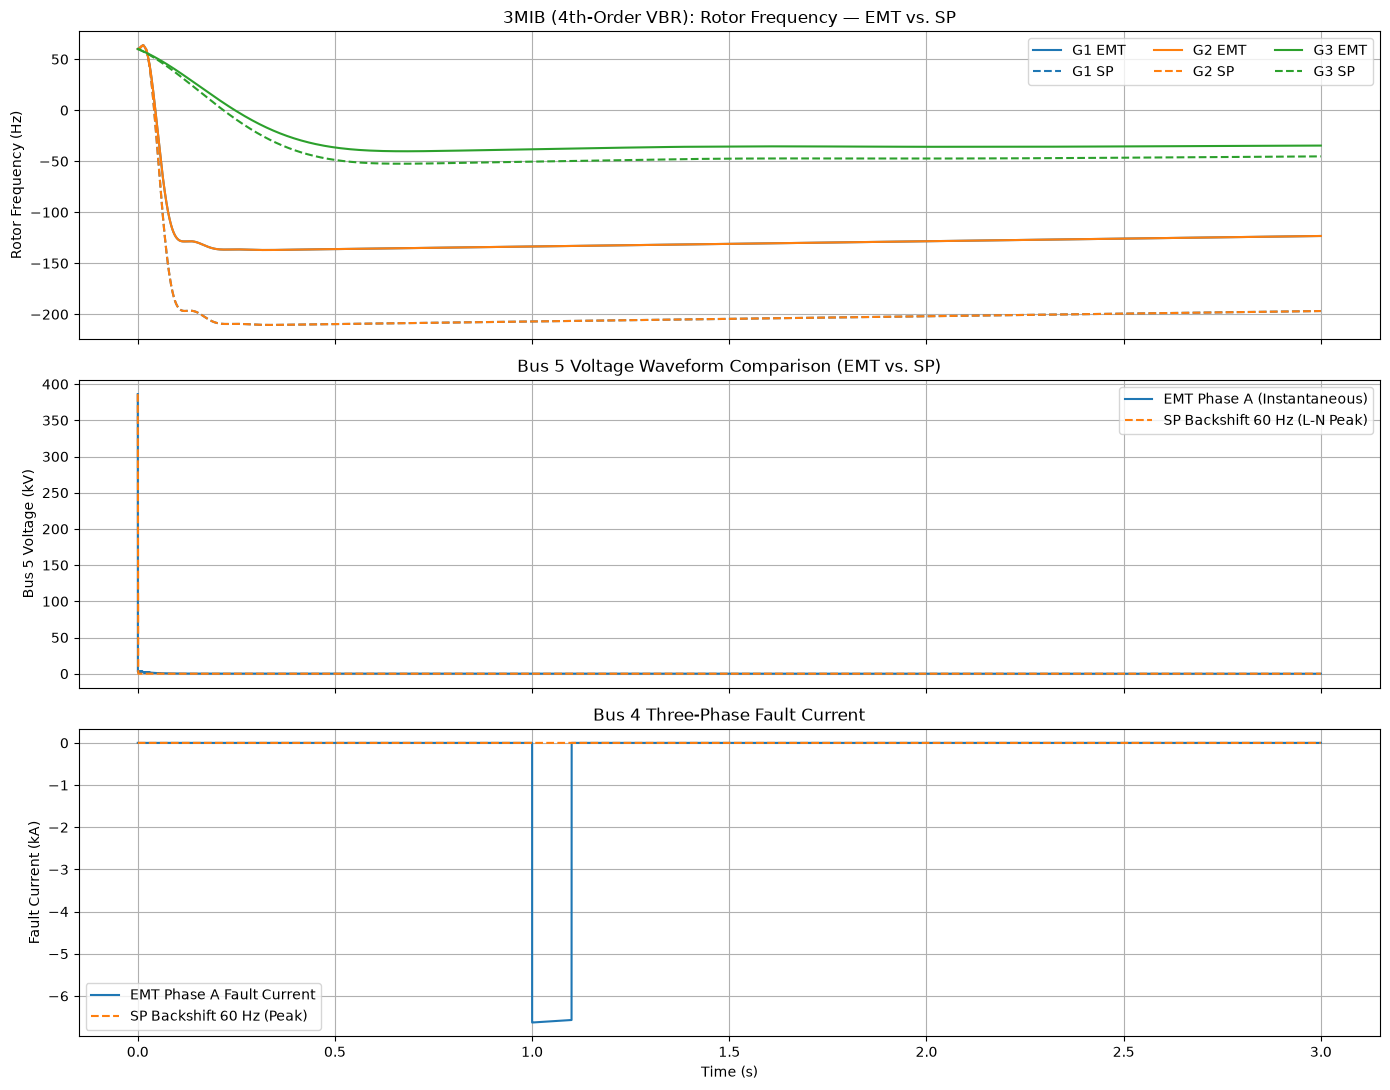

In [6]:
ts_sp  = rt.read_timeseries_dpsim(f"logs/{sim_name_sp}/{sim_name_sp}.csv")
ts_emt = rt.read_timeseries_dpsim(f"logs/{sim_name_emt}/{sim_name_emt}.csv")

fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)

# 1. Rotor Frequency Comparison (Hz)
for bus, color in zip((1, 2, 3), ("tab:blue", "tab:orange", "tab:green")):
    axes[0].plot(ts_emt[f"wr_gen{bus}"].time, np.real(ts_emt[f"wr_gen{bus}"].values) * F_NOM,
                 color=color, label=f"G{bus} EMT")
    axes[0].plot(ts_sp[f"wr_gen{bus}"].time, np.real(ts_sp[f"wr_gen{bus}"].values) * F_NOM,
                 "--", color=color, label=f"G{bus} SP")
axes[0].set_ylabel("Rotor Frequency (Hz)")
axes[0].set_title("3MIB (4th-Order VBR): Rotor Frequency — EMT vs. SP")
axes[0].grid(True)
axes[0].legend(ncol=3)

# 2. Bus 5 Voltage: Instantaneous EMT Phase A vs. 60 Hz Reconstructed SP Waveform
scale_ll_rms_to_ln_peak = np.sqrt(2.0 / 3.0)
sp_v5_wave = ts_sp["v_bus5"].interpolate(time_step_emt).frequency_shift(F_NOM)
axes[1].plot(ts_emt["v_bus5_0"].time, np.real(ts_emt["v_bus5_0"].values) / 1e3,
             label="EMT Phase A (Instantaneous)")
axes[1].plot(sp_v5_wave.time, np.real(sp_v5_wave.values) * scale_ll_rms_to_ln_peak / 1e3,
             "--", label="SP Backshift 60 Hz (L-N Peak)")
axes[1].set_ylabel("Bus 5 Voltage (kV)")
axes[1].set_title("Bus 5 Voltage Waveform Comparison (EMT vs. SP)")
axes[1].grid(True)
axes[1].legend()

# 3. Bus 4 Fault Current: Asymmetric DC Offset (EMT) vs. Reconstructed SP Waveform
sp_ifault_wave = ts_sp["i_fault"].interpolate(time_step_emt).frequency_shift(F_NOM)
axes[2].plot(ts_emt["i_fault"].time, np.real(ts_emt["i_fault"].values) / 1e3,
             label="EMT Phase A Fault Current")
axes[2].plot(sp_ifault_wave.time, np.real(sp_ifault_wave.values) * np.sqrt(2.0) / 1e3,
             "--", label="SP Backshift 60 Hz (Peak)")
axes[2].set_ylabel("Fault Current (kA)")
axes[2].set_xlabel("Time (s)")
axes[2].set_title("Bus 4 Three-Phase Fault Current")
axes[2].grid(True)
axes[2].legend()

fig.tight_layout()
plt.show()